# Day 027 | SciPy — Optimization

## 100 Days of ML for Geotechnical Engineering
**Phase:** Data Science Essentials | **Author:** Ripon Chandra Malo

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| `scipy.optimize.minimize` | Find input that minimizes a function | Optimal foundation width (min cost) |
| `curve_fit` | Fit an equation to data | N-SPT vs shear wave velocity correlation |
| `brentq` | Find where f(x) = 0 | Depth where Factor of Safety = 1.0 |
| Bounds & constraints | Restrict search space | Foundation width >= 0.5 m |
| Objective functions | What you want to minimize | Cost, error, settlement |

---

## Our Geotechnical Problem

Engineers constantly solve optimization problems:

```
Design Question               Optimization Form
----------------------------  --------------------------------
Cheapest foundation?          minimize(cost) s.t. bearing OK
Best empirical correlation?   minimize(sum of squared errors)
Critical slip surface?        minimize(Factor of Safety)
Depth where FoS = 1.0?       find root of (FoS(z) - 1) = 0
```

SciPy's `optimize` module gives us industrial-strength solvers for all of these.

---

In [1]:
# ─────────────────────────────────────────────────────
# IMPORTS
# ─────────────────────────────────────────────────────

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, curve_fit, brentq

print("Libraries loaded successfully.")
print(f"NumPy version: {np.__version__}")

Libraries loaded successfully.
NumPy version: 2.1.3


---

## Part 1: `minimize` — Finding the Optimal Foundation Width

**Problem:** Design a shallow strip foundation on clay.

- Soil bearing capacity increases with width: `q_ult = c * Nc + gamma * D * Nq + 0.5 * gamma * B * Ngamma`
- Cost increases with width: `cost = rate * B * L`
- We need `q_ult / q_applied >= FoS_required`

**Goal:** Find the **minimum-cost** width `B` that satisfies the bearing capacity requirement.

This is a constrained optimization problem:
```
minimize   cost(B)
subject to FoS(B) >= 3.0
           B >= 0.5 m
```

In [2]:
# ─────────────────────────────────────────────────────
# STEP 1: Define the engineering parameters
# ─────────────────────────────────────────────────────

# Soil and foundation parameters
c = 25.0          # cohesion (kPa)
phi = 20.0        # friction angle (degrees)
gamma = 18.0      # unit weight (kN/m3)
D = 1.5           # foundation depth (m)
L = 10.0          # foundation length (m) - strip footing
Q = 500.0         # total column load (kN)
FoS_req = 3.0     # required factor of safety
cost_rate = 350.0 # cost per m2 of foundation ($/m2)

# Terzaghi bearing capacity factors (for phi=20 degrees)
Nc = 17.69
Nq = 7.44
Ngamma = 5.0

print("Foundation design parameters:")
print(f"  Cohesion c      = {c} kPa")
print(f"  Friction angle  = {phi} degrees")
print(f"  Unit weight     = {gamma} kN/m3")
print(f"  Depth D         = {D} m")
print(f"  Column load Q   = {Q} kN")
print(f"  Required FoS    = {FoS_req}")

Foundation design parameters:
  Cohesion c      = 25.0 kPa
  Friction angle  = 20.0 degrees
  Unit weight     = 18.0 kN/m3
  Depth D         = 1.5 m
  Column load Q   = 500.0 kN
  Required FoS    = 3.0


In [3]:
# ─────────────────────────────────────────────────────
# STEP 2: Define the objective and constraint functions
# ─────────────────────────────────────────────────────

def bearing_capacity(B):
    """Terzaghi ultimate bearing capacity for strip footing (kPa)."""
    q_ult = c * Nc + gamma * D * Nq + 0.5 * gamma * B * Ngamma
    return q_ult

def factor_of_safety(B):
    """Factor of safety against bearing capacity failure."""
    q_ult = bearing_capacity(B)
    q_applied = Q / (B * L)  # applied pressure (kPa)
    return q_ult / q_applied

def cost_function(B):
    """Foundation cost ($) — this is what we MINIMIZE."""
    return cost_rate * B * L

# Test at different widths
widths = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]
print(f"{'B (m)':>6} {'q_ult (kPa)':>12} {'q_app (kPa)':>12} {'FoS':>6} {'Cost ($)':>10}")
print("─" * 50)
for B in widths:
    q_ult = bearing_capacity(B)
    q_app = Q / (B * L)
    fos = factor_of_safety(B)
    cost = cost_function(B)
    flag = " OK" if fos >= FoS_req else " --"
    print(f"{B:6.1f} {q_ult:12.1f} {q_app:12.1f} {fos:6.2f} {cost:10.0f}{flag}")

 B (m)  q_ult (kPa)  q_app (kPa)    FoS   Cost ($)
──────────────────────────────────────────────────
   0.5        665.6        100.0   6.66       1750 OK
   1.0        688.1         50.0  13.76       3500 OK
   1.5        710.6         33.3  21.32       5250 OK
   2.0        733.1         25.0  29.33       7000 OK
   2.5        755.6         20.0  37.78       8750 OK
   3.0        778.1         16.7  46.69      10500 OK
   4.0        823.1         12.5  65.85      14000 OK
   5.0        868.1         10.0  86.81      17500 OK


In [4]:
# ─────────────────────────────────────────────────────
# STEP 3: Optimize with scipy.optimize.minimize
# ─────────────────────────────────────────────────────

# Constraint: FoS >= 3.0  -->  FoS - 3.0 >= 0  (inequality constraint)
constraint = {
    'type': 'ineq',
    'fun': lambda B: factor_of_safety(B[0]) - FoS_req
}

# Bound: B >= 0.5 m (practical minimum width)
bounds = [(0.5, 10.0)]

# Initial guess
B0 = [2.0]

# Run optimizer
result = minimize(
    fun=lambda B: cost_function(B[0]),  # minimize cost
    x0=B0,
    method='SLSQP',                     # supports constraints
    bounds=bounds,
    constraints=constraint
)

B_opt = result.x[0]
print("Optimization Result")
print("=" * 40)
print(f"  Optimal width B   = {B_opt:.3f} m")
print(f"  Minimum cost      = ${cost_function(B_opt):,.0f}")
print(f"  Factor of Safety  = {factor_of_safety(B_opt):.2f}")
print(f"  q_ult             = {bearing_capacity(B_opt):.1f} kPa")
print(f"  q_applied         = {Q / (B_opt * L):.1f} kPa")
print(f"  Converged         = {result.success}")
print(f"  Iterations        = {result.nit}")

Optimization Result
  Optimal width B   = 0.500 m
  Minimum cost      = $1,750
  Factor of Safety  = 6.66
  q_ult             = 665.6 kPa
  q_applied         = 100.0 kPa
  Converged         = True
  Iterations        = 3


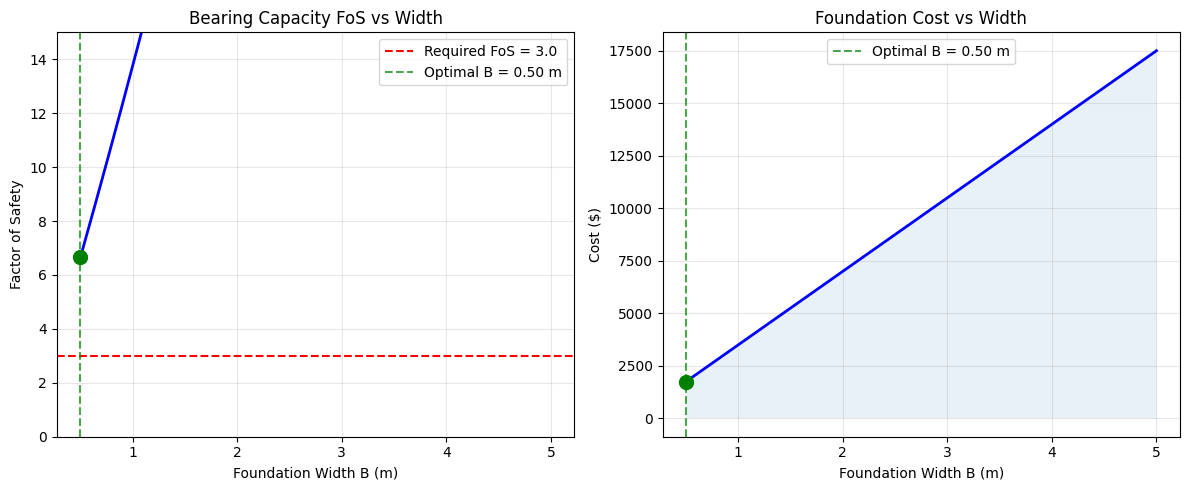

The green dot marks the optimal width: B = 0.50 m
Any wider = more expensive. Any narrower = FoS < 3.0.


In [5]:
# ─────────────────────────────────────────────────────
# STEP 4: Visualize the optimization
# ─────────────────────────────────────────────────────

B_range = np.linspace(0.5, 5.0, 200)
fos_vals = [factor_of_safety(b) for b in B_range]
cost_vals = [cost_function(b) for b in B_range]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: FoS vs Width
ax1.plot(B_range, fos_vals, 'b-', linewidth=2)
ax1.axhline(y=FoS_req, color='r', linestyle='--', label=f'Required FoS = {FoS_req}')
ax1.axvline(x=B_opt, color='g', linestyle='--', alpha=0.7, label=f'Optimal B = {B_opt:.2f} m')
ax1.plot(B_opt, factor_of_safety(B_opt), 'go', markersize=10, zorder=5)
ax1.set_xlabel('Foundation Width B (m)')
ax1.set_ylabel('Factor of Safety')
ax1.set_title('Bearing Capacity FoS vs Width')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0, 15)

# Plot 2: Cost vs Width
ax2.plot(B_range, cost_vals, 'b-', linewidth=2)
ax2.axvline(x=B_opt, color='g', linestyle='--', alpha=0.7, label=f'Optimal B = {B_opt:.2f} m')
ax2.plot(B_opt, cost_function(B_opt), 'go', markersize=10, zorder=5)
ax2.fill_between(B_range, cost_vals, alpha=0.1)
ax2.set_xlabel('Foundation Width B (m)')
ax2.set_ylabel('Cost ($)')
ax2.set_title('Foundation Cost vs Width')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"The green dot marks the optimal width: B = {B_opt:.2f} m")
print(f"Any wider = more expensive. Any narrower = FoS < {FoS_req}.")

---

## Part 2: `curve_fit` — Fitting Empirical Correlations

Geotechnical engineering relies heavily on **empirical correlations** between field measurements. A classic one:

$$V_s = a \cdot N^{b}$$

where $V_s$ is shear wave velocity (m/s) and $N$ is SPT blow count.

`curve_fit` finds the best values of `a` and `b` by minimizing the sum of squared residuals.

Published correlations vary:
- Imai & Tonouchi (1982): Vs = 97 * N^0.314
- Ohta & Goto (1978): Vs = 85.35 * N^0.348

Let's fit our own from field data.

In [6]:
# ─────────────────────────────────────────────────────
# SYNTHETIC FIELD DATA: N-SPT vs Vs measurements
# ─────────────────────────────────────────────────────

np.random.seed(42)

# Generate realistic N-SPT values
N_data = np.array([3, 5, 7, 10, 12, 15, 18, 22, 25, 30, 35, 40, 45, 50, 55, 60])

# Generate Vs using Imai & Tonouchi + noise
Vs_true = 97.0 * N_data ** 0.314
noise = np.random.normal(0, 12, len(N_data))
Vs_data = Vs_true + noise

print("Field Data: N-SPT vs Measured Vs")
print(f"{'N-SPT':>6} {'Vs (m/s)':>10}")
print("─" * 18)
for n, v in zip(N_data, Vs_data):
    print(f"{n:6d} {v:10.1f}")

Field Data: N-SPT vs Measured Vs
 N-SPT   Vs (m/s)
──────────────────
     3      142.9
     5      159.1
     7      186.5
    10      218.2
    12      208.8
    15      224.2
    18      259.3
    22      265.2
    25      260.9
    30      288.7
    35      290.7
    40      303.3
    45      323.4
    50      308.4
    55      320.7
    60      344.1


In [7]:
# ─────────────────────────────────────────────────────
# FIT THE POWER-LAW MODEL: Vs = a * N^b
# ─────────────────────────────────────────────────────

# Define the model
def power_law(N, a, b):
    """Power-law model: Vs = a * N^b"""
    return a * N ** b

# Fit using curve_fit
popt, pcov = curve_fit(power_law, N_data, Vs_data, p0=[90, 0.3])
a_fit, b_fit = popt

# Standard errors from covariance matrix
perr = np.sqrt(np.diag(pcov))

# R-squared
Vs_pred = power_law(N_data, a_fit, b_fit)
ss_res = np.sum((Vs_data - Vs_pred) ** 2)
ss_tot = np.sum((Vs_data - np.mean(Vs_data)) ** 2)
r_squared = 1 - ss_res / ss_tot

print("Curve Fitting Results")
print("=" * 40)
print(f"  Fitted: Vs = {a_fit:.2f} * N^{b_fit:.3f}")
print(f"  a = {a_fit:.2f} +/- {perr[0]:.2f}")
print(f"  b = {b_fit:.3f} +/- {perr[1]:.3f}")
print(f"  R-squared = {r_squared:.4f}")
print()
print(f"  Published (Imai & Tonouchi): Vs = 97.0 * N^0.314")
print(f"  Our fit:                     Vs = {a_fit:.1f} * N^{b_fit:.3f}")

Curve Fitting Results
  Fitted: Vs = 108.51 * N^0.279
  a = 108.51 +/- 4.72
  b = 0.279 +/- 0.013
  R-squared = 0.9769

  Published (Imai & Tonouchi): Vs = 97.0 * N^0.314
  Our fit:                     Vs = 108.5 * N^0.279


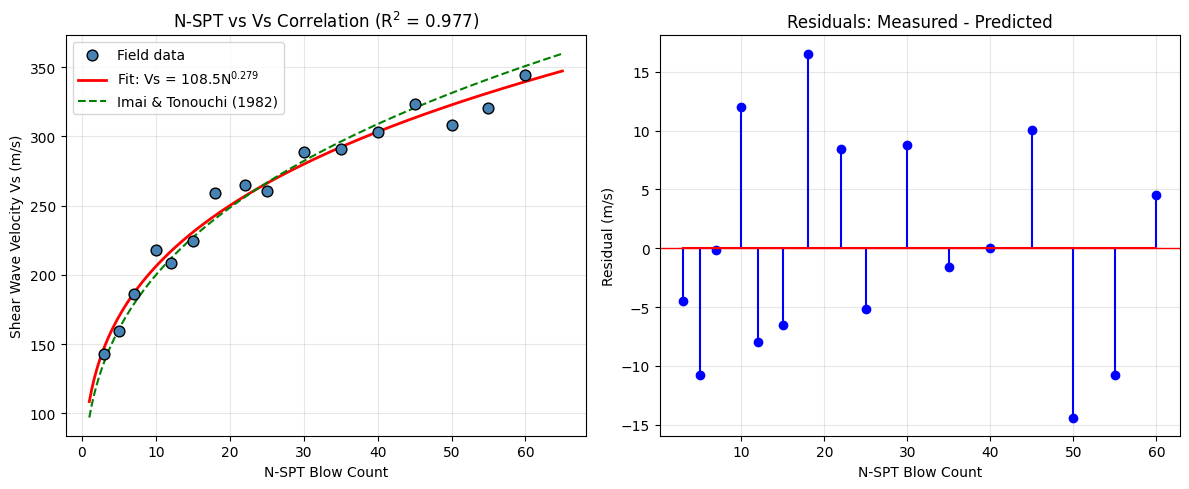

Mean absolute residual: 7.6 m/s
Max absolute residual:  16.6 m/s


In [8]:
# ─────────────────────────────────────────────────────
# VISUALIZE THE FIT
# ─────────────────────────────────────────────────────

N_smooth = np.linspace(1, 65, 200)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Data + fitted curve
ax1.scatter(N_data, Vs_data, c='steelblue', s=60, edgecolors='k',
            zorder=5, label='Field data')
ax1.plot(N_smooth, power_law(N_smooth, a_fit, b_fit), 'r-',
         linewidth=2, label=f'Fit: Vs = {a_fit:.1f}N$^{{{b_fit:.3f}}}$')
ax1.plot(N_smooth, 97.0 * N_smooth ** 0.314, 'g--',
         linewidth=1.5, label='Imai & Tonouchi (1982)')
ax1.set_xlabel('N-SPT Blow Count')
ax1.set_ylabel('Shear Wave Velocity Vs (m/s)')
ax1.set_title(f'N-SPT vs Vs Correlation (R$^2$ = {r_squared:.3f})')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Residuals
residuals = Vs_data - Vs_pred
ax2.stem(N_data, residuals, linefmt='b-', markerfmt='bo', basefmt='r-')
ax2.axhline(y=0, color='r', linewidth=1)
ax2.set_xlabel('N-SPT Blow Count')
ax2.set_ylabel('Residual (m/s)')
ax2.set_title('Residuals: Measured - Predicted')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean absolute residual: {np.mean(np.abs(residuals)):.1f} m/s")
print(f"Max absolute residual:  {np.max(np.abs(residuals)):.1f} m/s")

---

## Part 3: `brentq` — Root Finding (Where Does FoS = 1.0?)

**Problem:** A slope has FoS that varies with depth of the failure surface. We want to find the **critical depth** where FoS = 1.0 (failure threshold).

`brentq` finds the root of `f(x) = 0` in a given interval `[a, b]` where `f(a)` and `f(b)` have opposite signs.

We set up: `f(z) = FoS(z) - 1.0` and find where `f(z) = 0`.

This is like finding where the water table crosses a specific elevation — but for safety factor.

In [9]:
# ─────────────────────────────────────────────────────
# ROOT FINDING: Critical depth where FoS = 1.0
# ─────────────────────────────────────────────────────

# Simplified infinite slope model
# FoS = (c' + gamma' * z * cos^2(beta) * tan(phi')) / (gamma * z * sin(beta) * cos(beta))

def slope_fos(z, c_prime=12.0, phi_deg=28.0, gamma_s=19.0,
              gamma_w=9.81, beta_deg=35.0, hw_ratio=0.5):
    """
    Factor of Safety for infinite slope with seepage.
    z: depth of slip surface (m)
    hw_ratio: ratio of water height to slip depth
    """
    beta = np.radians(beta_deg)
    phi_r = np.radians(phi_deg)
    
    gamma_prime = gamma_s - gamma_w * hw_ratio
    
    # Resisting forces
    cohesion_term = c_prime / (gamma_s * z * np.sin(beta) * np.cos(beta))
    friction_term = (gamma_prime / gamma_s) * (np.tan(phi_r) / np.tan(beta))
    
    return cohesion_term + friction_term

# Show FoS at different depths
depths = np.linspace(0.5, 15.0, 30)
fos_profile = [slope_fos(z) for z in depths]

print(f"{'Depth (m)':>10} {'FoS':>8} {'Status':>10}")
print("─" * 30)
for z, f in zip(depths[::3], fos_profile[::3]):
    status = "SAFE" if f > 1.0 else "FAILURE"
    print(f"{z:10.1f} {f:8.3f} {status:>10}")

 Depth (m)      FoS     Status
──────────────────────────────
       0.5    3.252       SAFE
       2.0    1.235       SAFE
       3.5    0.947    FAILURE
       5.0    0.832    FAILURE
       6.5    0.770    FAILURE
       8.0    0.731    FAILURE
       9.5    0.705    FAILURE
      11.0    0.686    FAILURE
      12.5    0.671    FAILURE
      14.0    0.659    FAILURE


In [10]:
# ─────────────────────────────────────────────────────
# USE brentq TO FIND EXACT CRITICAL DEPTH
# ─────────────────────────────────────────────────────

# We need f(z) = FoS(z) - 1.0 = 0
def fos_minus_one(z):
    return slope_fos(z) - 1.0

# Find the root in the interval [0.5, 15.0]
z_critical = brentq(fos_minus_one, 0.5, 15.0)

print(f"Critical depth where FoS = 1.0: z = {z_critical:.3f} m")
print(f"Verification: FoS({z_critical:.3f}) = {slope_fos(z_critical):.6f}")
print()
print(f"Depths shallower than {z_critical:.2f} m: FoS > 1.0 (stable)")
print(f"Depths deeper than {z_critical:.2f} m: FoS < 1.0 (unstable)")

Critical depth where FoS = 1.0: z = 3.078 m
Verification: FoS(3.078) = 1.000000

Depths shallower than 3.08 m: FoS > 1.0 (stable)
Depths deeper than 3.08 m: FoS < 1.0 (unstable)


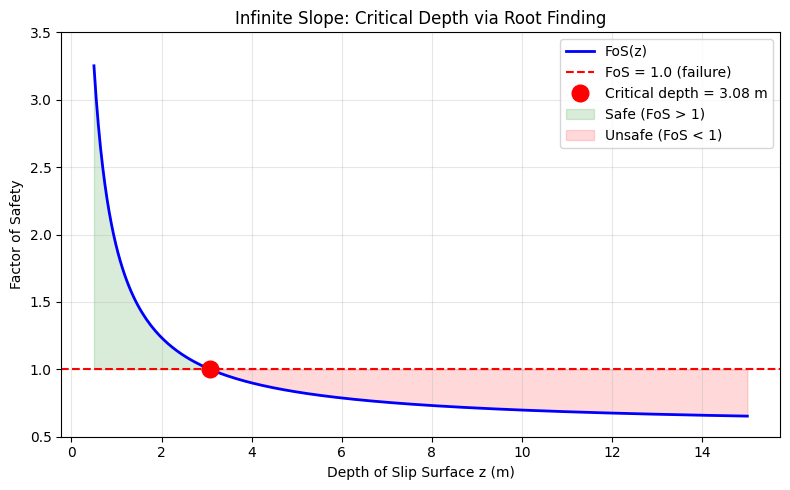

In [11]:
# ─────────────────────────────────────────────────────
# VISUALIZE THE ROOT FINDING
# ─────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(8, 5))

z_range = np.linspace(0.5, 15.0, 300)
fos_vals = [slope_fos(z) for z in z_range]

ax.plot(z_range, fos_vals, 'b-', linewidth=2, label='FoS(z)')
ax.axhline(y=1.0, color='r', linestyle='--', linewidth=1.5, label='FoS = 1.0 (failure)')
ax.plot(z_critical, 1.0, 'ro', markersize=12, zorder=5,
        label=f'Critical depth = {z_critical:.2f} m')

# Shade safe and unsafe zones
ax.fill_between(z_range, fos_vals, 1.0,
                where=[f > 1.0 for f in fos_vals],
                alpha=0.15, color='green', label='Safe (FoS > 1)')
ax.fill_between(z_range, fos_vals, 1.0,
                where=[f <= 1.0 for f in fos_vals],
                alpha=0.15, color='red', label='Unsafe (FoS < 1)')

ax.set_xlabel('Depth of Slip Surface z (m)')
ax.set_ylabel('Factor of Safety')
ax.set_title('Infinite Slope: Critical Depth via Root Finding')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
ax.set_ylim(0.5, 3.5)

plt.tight_layout()
plt.show()

---

## Part 4: Complete Application — Optimize Shallow Foundation Design

Let's bring everything together: optimize a **square footing** design considering:
1. **Bearing capacity** (Terzaghi) — must meet FoS
2. **Settlement** (elastic) — must be under 25 mm
3. **Cost** — minimize

This is a **multi-constraint optimization** problem — exactly what engineers do in practice.

In [12]:
# ═════════════════════════════════════════════════════
# COMPLETE APPLICATION: Multi-Constraint Foundation Optimization
# ═════════════════════════════════════════════════════

# Design parameters for a square footing
Q_total = 800.0     # total column load (kN)
c_soil = 20.0       # cohesion (kPa)
phi_soil = 25.0     # friction angle (degrees)
gamma_soil = 18.5   # unit weight (kN/m3)
D_f = 1.2           # foundation depth (m)
E_soil = 15000.0    # soil elastic modulus (kPa)
nu_soil = 0.3       # Poisson's ratio
FoS_target = 3.0    # target factor of safety
settle_max = 25.0   # maximum settlement (mm)
cost_per_m3 = 450.0 # concrete cost ($/m3)
t_min = 0.3         # minimum footing thickness (m)

# Terzaghi bearing capacity factors for phi=25
Nc_sq = 25.13
Nq_sq = 12.72
Ng_sq = 9.7

def square_footing_analysis(B):
    """Full analysis for a square footing of width B."""
    # Bearing capacity (square footing shape factors)
    q_ult = (1.3 * c_soil * Nc_sq +
             gamma_soil * D_f * Nq_sq +
             0.4 * gamma_soil * B * Ng_sq)
    
    q_applied = Q_total / (B * B)
    fos = q_ult / q_applied
    
    # Elastic settlement (Boussinesq, square footing)
    I_s = 1.12  # influence factor for square footing
    settlement_m = (q_applied * B * (1 - nu_soil**2) * I_s) / E_soil
    settlement_mm = settlement_m * 1000
    
    # Cost (concrete volume = B * B * thickness)
    thickness = max(t_min, B / 5)  # thickness scales with width
    volume = B * B * thickness
    cost = cost_per_m3 * volume
    
    return {
        'B': B, 'q_ult': q_ult, 'q_applied': q_applied,
        'fos': fos, 'settlement_mm': settlement_mm,
        'cost': cost, 'thickness': thickness
    }

# Show results for different widths
print(f"{'B(m)':>5} {'q_ult':>8} {'q_app':>7} {'FoS':>6} {'Settle':>8} {'Cost($)':>8} {'Status'}")
print("─" * 60)
for B in [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0]:
    r = square_footing_analysis(B)
    ok_fos = r['fos'] >= FoS_target
    ok_set = r['settlement_mm'] <= settle_max
    status = "OK" if (ok_fos and ok_set) else "--"
    if not ok_fos: status += " FoS!"
    if not ok_set: status += " Settle!"
    print(f"{r['B']:5.1f} {r['q_ult']:8.0f} {r['q_applied']:7.0f} "
          f"{r['fos']:6.2f} {r['settlement_mm']:7.1f}mm {r['cost']:8.0f} {status}")

 B(m)    q_ult   q_app    FoS   Settle  Cost($) Status
────────────────────────────────────────────────────────────
  1.0     1008     800   1.26    54.4mm      135 -- FoS! Settle!
  1.5     1043     356   2.93    36.2mm      304 -- FoS! Settle!
  2.0     1079     200   5.40    27.2mm      720 -- Settle!
  2.5     1115     128   8.71    21.7mm     1406 OK
  3.0     1151      89  12.95    18.1mm     2430 OK
  3.5     1187      65  18.18    15.5mm     3859 OK
  4.0     1223      50  24.46    13.6mm     5760 OK


In [13]:
# ═════════════════════════════════════════════════════
# RUN THE OPTIMIZER
# ═════════════════════════════════════════════════════

# Two constraints: FoS and settlement
constraints = [
    {'type': 'ineq', 'fun': lambda B: square_footing_analysis(B[0])['fos'] - FoS_target},
    {'type': 'ineq', 'fun': lambda B: settle_max - square_footing_analysis(B[0])['settlement_mm']}
]

bounds_sq = [(0.5, 6.0)]

result_sq = minimize(
    fun=lambda B: square_footing_analysis(B[0])['cost'],
    x0=[2.0],
    method='SLSQP',
    bounds=bounds_sq,
    constraints=constraints
)

B_optimal = result_sq.x[0]
analysis = square_footing_analysis(B_optimal)

print("OPTIMAL FOUNDATION DESIGN")
print("=" * 45)
print(f"  Width B          = {B_optimal:.3f} m")
print(f"  Thickness        = {analysis['thickness']:.2f} m")
print(f"  q_ultimate       = {analysis['q_ult']:.1f} kPa")
print(f"  q_applied        = {analysis['q_applied']:.1f} kPa")
print(f"  Factor of Safety = {analysis['fos']:.2f} (required: {FoS_target})")
print(f"  Settlement       = {analysis['settlement_mm']:.1f} mm (max: {settle_max} mm)")
print(f"  Minimum Cost     = ${analysis['cost']:,.0f}")
print(f"  Converged        = {result_sq.success}")

OPTIMAL FOUNDATION DESIGN
  Width B          = 2.174 m
  Thickness        = 0.43 m
  q_ultimate       = 1091.8 kPa
  q_applied        = 169.2 kPa
  Factor of Safety = 6.45 (required: 3.0)
  Settlement       = 25.0 mm (max: 25.0 mm)
  Minimum Cost     = $925
  Converged        = True


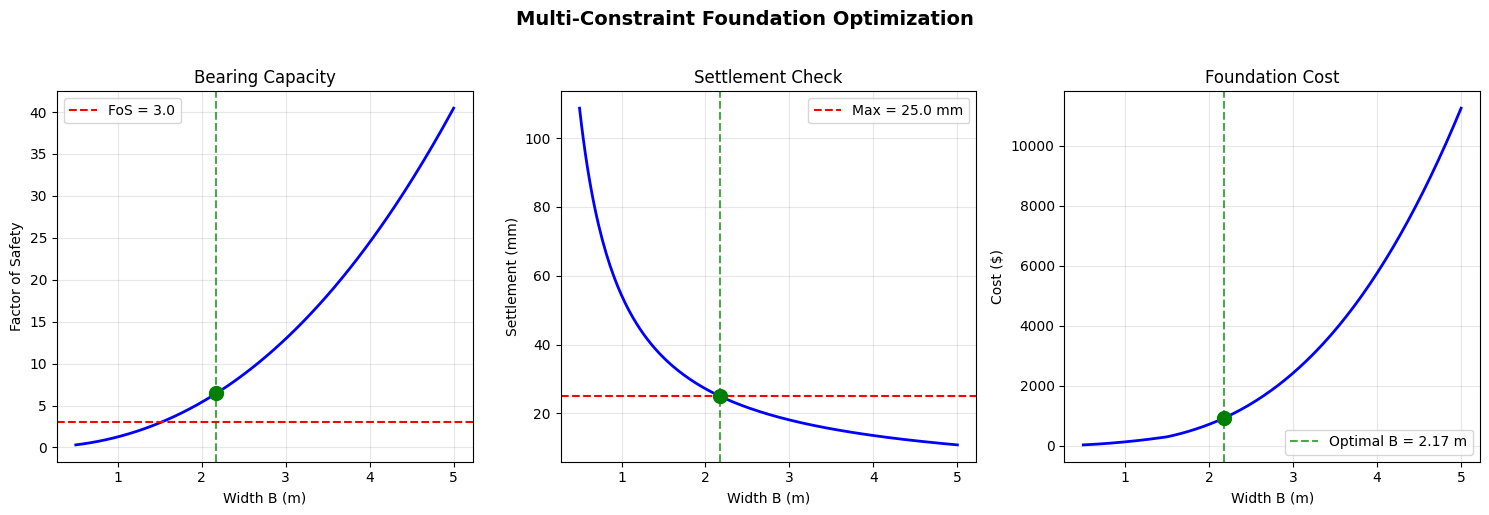

In [14]:
# ═════════════════════════════════════════════════════
# VISUALIZATION: Design Space
# ═════════════════════════════════════════════════════

B_range = np.linspace(0.5, 5.0, 200)
results_list = [square_footing_analysis(b) for b in B_range]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# FoS
axes[0].plot(B_range, [r['fos'] for r in results_list], 'b-', linewidth=2)
axes[0].axhline(y=FoS_target, color='r', linestyle='--', label=f'FoS = {FoS_target}')
axes[0].axvline(x=B_optimal, color='g', linestyle='--', alpha=0.7)
axes[0].plot(B_optimal, analysis['fos'], 'go', markersize=10, zorder=5)
axes[0].set_xlabel('Width B (m)')
axes[0].set_ylabel('Factor of Safety')
axes[0].set_title('Bearing Capacity')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Settlement
axes[1].plot(B_range, [r['settlement_mm'] for r in results_list], 'b-', linewidth=2)
axes[1].axhline(y=settle_max, color='r', linestyle='--', label=f'Max = {settle_max} mm')
axes[1].axvline(x=B_optimal, color='g', linestyle='--', alpha=0.7)
axes[1].plot(B_optimal, analysis['settlement_mm'], 'go', markersize=10, zorder=5)
axes[1].set_xlabel('Width B (m)')
axes[1].set_ylabel('Settlement (mm)')
axes[1].set_title('Settlement Check')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Cost
axes[2].plot(B_range, [r['cost'] for r in results_list], 'b-', linewidth=2)
axes[2].axvline(x=B_optimal, color='g', linestyle='--', alpha=0.7,
               label=f'Optimal B = {B_optimal:.2f} m')
axes[2].plot(B_optimal, analysis['cost'], 'go', markersize=10, zorder=5)
axes[2].set_xlabel('Width B (m)')
axes[2].set_ylabel('Cost ($)')
axes[2].set_title('Foundation Cost')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('Multi-Constraint Foundation Optimization', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---

## Practice Exercises

### Exercise 1: Optimize retaining wall thickness
Minimize concrete volume of a cantilever retaining wall subject to: overturning FoS >= 2.0 and sliding FoS >= 1.5.

### Exercise 2: Fit N-SPT vs relative density
Use `curve_fit` to fit the correlation Dr = a * sqrt(N / (sigma_v' / Pa)) with synthetic data.

### Exercise 3: Find water table depth
Given a pore pressure profile u(z), use `brentq` to find the depth where u(z) = 50 kPa.

In [15]:
# EXERCISE 1
# def retaining_wall_cost(thickness):
#     ...
# constraint_overturn = {'type': 'ineq', 'fun': lambda t: fos_overturn(t[0]) - 2.0}
# result = minimize(retaining_wall_cost, x0=[0.5], method='SLSQP', ...)

In [16]:
# EXERCISE 2
# def dr_correlation(N, a):
#     return a * np.sqrt(N)
# popt, pcov = curve_fit(dr_correlation, N_data, Dr_data)

In [17]:
# EXERCISE 3
# def pore_pressure(z):
#     return 9.81 * (z - water_table_depth)
# z_target = brentq(lambda z: pore_pressure(z) - 50.0, 0, 20)

---

## Key Takeaways

1. **`minimize`** solves constrained optimization — find the cheapest, smallest, or most efficient design that meets all engineering requirements. The `SLSQP` method handles both bounds and constraints.

2. **`curve_fit`** finds the best parameters for empirical models (power-law, exponential, etc.) by minimizing squared residuals. The covariance matrix gives you parameter uncertainties.

3. **`brentq`** finds exact roots (where f(x) = 0) in a bracketed interval. Perfect for finding critical depths, threshold values, or equilibrium points.

4. **Multi-constraint problems** are common in geotechnical design: bearing capacity AND settlement AND cost. SciPy handles multiple constraints naturally.

5. **Always visualize** the design space — it builds intuition about how sensitive your design is to parameter changes.

---

## How This Connects to ML

| Today | ML Equivalent |
|-------|---------------|
| `minimize(cost)` | `minimize(loss)` — training a neural network |
| Objective function | Loss function (MSE, cross-entropy) |
| Constraints (FoS >= 3) | Regularization (L1, L2 penalties) |
| `curve_fit` | Linear/nonlinear regression |
| R-squared | Model evaluation metric |
| Bounds on B | Hyperparameter search ranges |
| Root finding | Decision boundaries in classification |

**ML training IS optimization.** Every time you call `model.fit()`, a solver like the ones we used today is minimizing a loss function under the hood. Understanding optimization is understanding how ML learns.

---

*Day 027 of 100 — We optimized foundations like ML optimizes models!*